Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, random_split
from torch.utils.data import DataLoader
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

import pandas as pd
 

Creating the NN

In [2]:
class Net(nn.Module):
    def __init__(self, d_in, dropout_rate=0.2):
        super(Net, self).__init__()

        # Tieferes und breiteres Netzwerk mit Batch Normalization
        self.fc1 = nn.Linear(d_in, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.dropout1 = nn.Dropout(dropout_rate)
        
        self.fc2 = nn.Linear(128, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.dropout2 = nn.Dropout(dropout_rate)
        
        self.fc3 = nn.Linear(128, 64)
        self.bn3 = nn.BatchNorm1d(64)
        self.dropout3 = nn.Dropout(dropout_rate)
        
        self.fc4 = nn.Linear(64, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.dropout4 = nn.Dropout(dropout_rate)
        
        self.fc5 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.dropout1(F.gelu(self.bn1(self.fc1(x))))
        x = self.dropout2(F.gelu(self.bn2(self.fc2(x))))
        x = self.dropout3(F.gelu(self.bn3(self.fc3(x))))
        x = self.dropout4(F.gelu(self.bn4(self.fc4(x))))
        x = self.fc5(x)
        return x


Load The Bates Model Parameters

**BATES Model (Heston + Jumps)**

Das Bates-Modell kombiniert stochastische Volatilität (wie Heston) mit Sprungprozessen:

**Heston-Parameter:**
- **v0**: Anfangsvolatilität
- **kappa**: Mean-Reversion-Geschwindigkeit
- **theta**: Langfristige Durchschnittsvolatilität
- **xi**: Volatilität der Volatilität
- **rho**: Korrelation zwischen Preis und Volatilität

**Jump-Parameter:**
- **jump_lambda** (λ): Sprungintensität (Häufigkeit der Sprünge)
- **jump_mu** (μ): Erwarteter Sprungeffekt
- **jump_delta** (δ): Volatilität der Sprünge

In [3]:
df_parquet_1 = pd.read_parquet("exotic_mc_dataset_1.parquet")
df_bates_selected_parquet_1 = df_parquet_1[df_parquet_1["model"] == "BATES"].loc[:, "option":"T"].join(
    df_parquet_1.loc[df_parquet_1["model"] == "BATES", "v0":"jump_delta"]
)

Y_parquet_1 = torch.tensor(df_bates_selected_parquet_1["price"].values, dtype=torch.float32).view(-1, 1)

opt_dummies_1 = pd.get_dummies(
    df_bates_selected_parquet_1["option"],
    prefix="opt"
).astype("int64")

num_cols = [
    "S0",
    "K",
    "r",
    "T",
    "v0",
    "kappa",
    "theta",
    "xi",
    "rho",
    "jump_lambda",
    "jump_mu",
    "jump_delta"
]

X_df_1 = pd.concat(
    [
        df_bates_selected_parquet_1[num_cols],
        opt_dummies_1
    ],
    axis=1
)

X_parquet_1 = torch.tensor(X_df_1.values, dtype=torch.float32)

X = torch.cat([X_parquet_1], dim=0)
Y = torch.cat([Y_parquet_1], dim=0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.numpy())
X = torch.tensor(X_scaled, dtype=torch.float32)

input_dim = X.shape[1]
torch.manual_seed(42)
net = Net(input_dim)

display(X.shape)
display(Y.shape)


torch.Size([3317, 18])

torch.Size([3317, 1])

In [4]:
X_df_1.head()

,S0,K,r,T,v0,kappa,theta,xi,rho,jump_lambda,jump_mu,jump_delta,opt_ASIAN_ARITH_CALL,opt_ASIAN_ARITH_PUT,opt_BARRIER_DOWN_AND_OUT_PUT,opt_BARRIER_UP_AND_OUT_CALL,opt_LOOKBACK_FLOAT_CALL,opt_LOOKBACK_FLOAT_PUT
2,114.000253,93.627851,0.044818,1.263542,0.275776,2.774970,0.113014,1.062984,-0.635500,0.968353,0.043360,0.471449,0,0,1,0,0,0
4,97.171672,87.049211,0.052065,1.098681,0.464715,2.603416,0.375134,0.765180,-0.110133,0.799838,-0.216613,0.482992,1,0,0,0,0,0
5,148.872831,136.963760,0.056302,1.474109,0.334268,1.280888,0.445425,0.794766,-0.918054,0.969186,-0.037182,0.440941,0,0,0,1,0,0
9,93.878220,149.779218,0.008078,1.621386,0.039981,2.064202,0.279191,0.710896,-0.178344,0.882755,-0.021326,0.303479,0,0,1,0,0,0
14,75.564751,50.347906,0.019745,1.748566,0.065678,1.912303,0.350629,1.745478,-0.809738,0.414444,0.046108,0.377504,0,0,0,0,0,1


In [5]:
print(f"Total: {len(X)} samples")
print(f"\nInput features: {input_dim}")
print(f"Feature names: {list(X_df_1.columns)}")

Total: 3317 samples

Input features: 18
Feature names: ['S0', 'K', 'r', 'T', 'v0', 'kappa', 'theta', 'xi', 'rho', 'jump_lambda', 'jump_mu', 'jump_delta', 'opt_ASIAN_ARITH_CALL', 'opt_ASIAN_ARITH_PUT', 'opt_BARRIER_DOWN_AND_OUT_PUT', 'opt_BARRIER_UP_AND_OUT_CALL', 'opt_LOOKBACK_FLOAT_CALL', 'opt_LOOKBACK_FLOAT_PUT']


Setting the DataLoader                                    

In [6]:
dataset = TensorDataset(X, Y)

# 70% Training, 15% Validation, 15% Test
n_total = len(dataset)
n_train = int(0.7 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

train_dataset, val_dataset, test_dataset = random_split(dataset, [n_train, n_val, n_test])

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Training samples: {n_train}")
print(f"Validation samples: {n_val}")
print(f"Test samples: {n_test}")


Training samples: 2321
Validation samples: 497
Test samples: 499


Define a Loss function and optimizer

In [7]:
criterion = nn.MSELoss()
optimizer = optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)

# Learning Rate Scheduler - reduziert LR wenn Validation Loss stagniert
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=10
)

Training the Network

Epoch [10/200] - Train Loss: 472.446880, Val Loss: 476.794259, LR: 0.001000
Epoch [20/200] - Train Loss: 220.867028, Val Loss: 219.511579, LR: 0.001000
Epoch [30/200] - Train Loss: 83.387177, Val Loss: 84.124107, LR: 0.001000
Epoch [40/200] - Train Loss: 46.229891, Val Loss: 43.973925, LR: 0.001000
Epoch [50/200] - Train Loss: 39.778434, Val Loss: 23.518883, LR: 0.001000
Epoch [60/200] - Train Loss: 36.762039, Val Loss: 26.346662, LR: 0.001000
Epoch [70/200] - Train Loss: 34.625665, Val Loss: 22.283184, LR: 0.000500
Epoch [80/200] - Train Loss: 36.124653, Val Loss: 23.353900, LR: 0.000500
Epoch [90/200] - Train Loss: 31.945419, Val Loss: 23.134859, LR: 0.000250
Epoch [100/200] - Train Loss: 38.446511, Val Loss: 29.269173, LR: 0.000250
Epoch [110/200] - Train Loss: 30.315944, Val Loss: 25.093572, LR: 0.000125

Early stopping at epoch 116
Best validation loss: 21.464442

Loaded best model from training
Finished Training


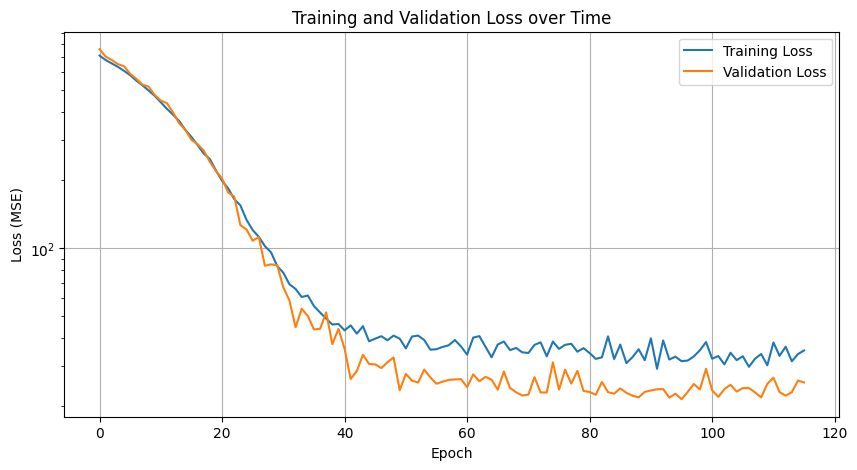

In [8]:

# Listen für Plotting
train_losses = []
val_losses = []

# Early Stopping Parameter
best_val_loss = float('inf')
patience = 20
patience_counter = 0
best_model_state = None

num_epochs = 200

for epoch in range(num_epochs):
    # Training Phase
    net.train()
    running_loss = 0.0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
    
    # Durchschnittlicher Training Loss
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    
    # Validation Phase
    net.eval()
    val_loss = 0.0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
    
    # Durchschnittlicher Validation Loss
    epoch_val_loss = val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    
    # Learning Rate Scheduler Step
    scheduler.step(epoch_val_loss)
    
    # Ausgabe alle 10 Epochen
    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}] - '
              f'Train Loss: {epoch_train_loss:.6f}, '
              f'Val Loss: {epoch_val_loss:.6f}, '
              f'LR: {optimizer.param_groups[0]["lr"]:.6f}')
    
    # Early Stopping Check
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0
        # Speichere bestes Modell
        best_model_state = net.state_dict().copy()
    else:
        patience_counter += 1
    
    if patience_counter >= patience:
        print(f'\nEarly stopping at epoch {epoch + 1}')
        print(f'Best validation loss: {best_val_loss:.6f}')
        break

# Lade bestes Modell
if best_model_state is not None:
    net.load_state_dict(best_model_state)
    print('\nLoaded best model from training')

print('Finished Training')

# Plot Training History
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss over Time')
plt.legend()
plt.grid(True)
plt.yscale('log')  # Log-Skala für bessere Sichtbarkeit
plt.show()


In [9]:
net.eval()

correct = 0
total = 0
tol = 0.05  # absolute tolerance

with torch.no_grad():
    for X, y in test_loader:
        preds = net(X).view_as(y)              # ensure shape matches (N,1)
        within = (preds - y).abs() <= tol      # boolean tensor
        correct += within.sum().item()
        total += y.numel()

acc = 100.0 * correct / total
print(f"Accuracy within ±{tol}: {acc:.2f}%")

Accuracy within ±0.05: 4.21%


In [10]:
net.eval()

correct = 0
total = 0
pct = 0.20  # 20%

eps = 1e-8  # avoid divide-by-zero
with torch.no_grad():
    for X, y in test_loader:
        preds = net(X).view_as(y)
        rel_err = (preds - y).abs() / (y.abs() + eps)
        within = rel_err <= pct
        correct += within.sum().item()
        total += y.numel()

acc = 100.0 * correct / total
print(f"Accuracy within ±{pct*100:.1f}%: {acc:.2f}%")

Accuracy within ±20.0%: 46.69%


Detaillierte Test-Evaluierung

TEST SET PERFORMANCE
Test MSE:  22.957912
Test RMSE: 4.791442
Test MAE:  2.545315
Test MAPE: 1486986300.00%
R² Score:  0.9466


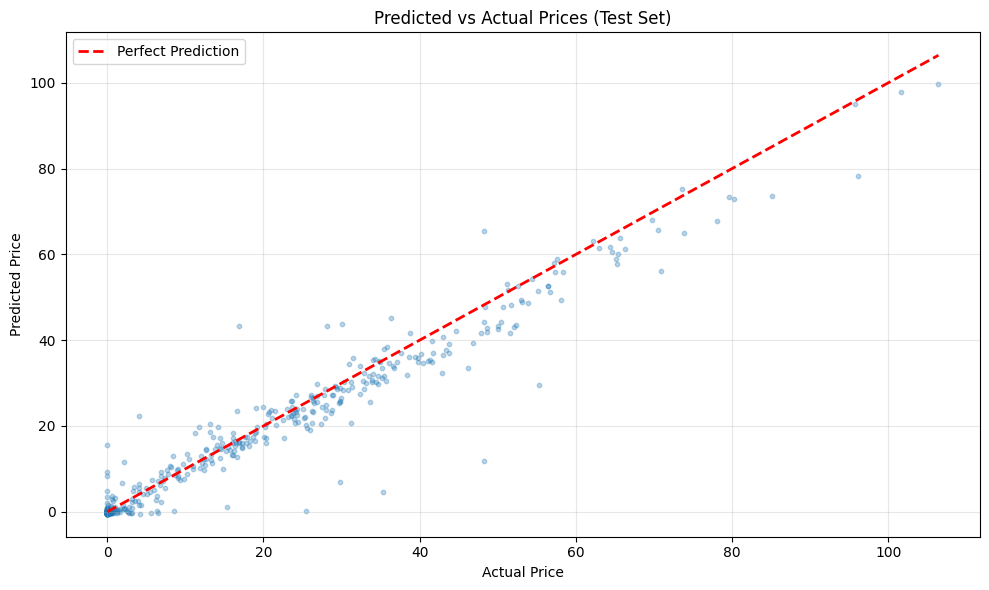

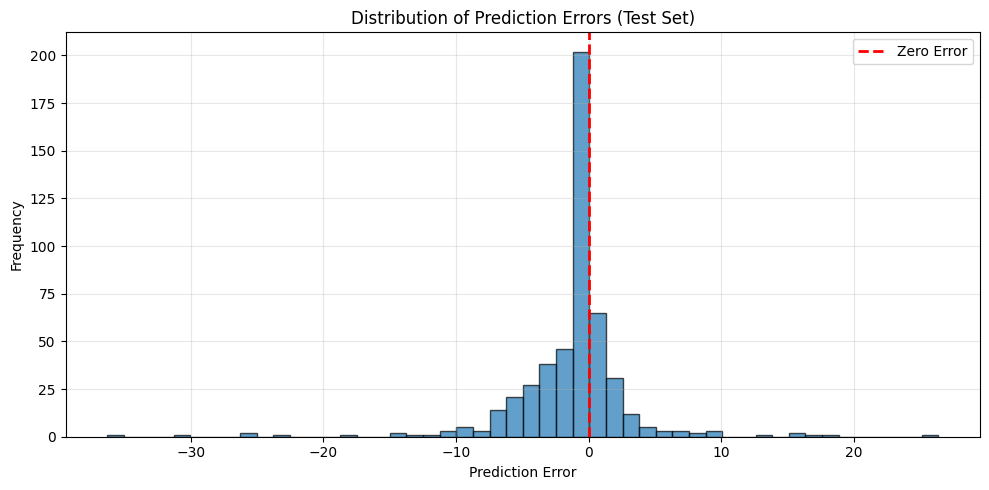

In [11]:
# Detaillierte Metriken auf Test-Set
net.eval()

all_preds = []
all_targets = []
test_loss = 0.0

with torch.no_grad():
    for X, y in test_loader:
        preds = net(X).view_as(y)
        all_preds.append(preds)
        all_targets.append(y)
        loss = criterion(preds, y)
        test_loss += loss.item() * X.size(0)

all_preds = torch.cat(all_preds)
all_targets = torch.cat(all_targets)

# Test MSE
test_mse = test_loss / len(test_loader.dataset)
test_rmse = test_mse ** 0.5

# Mean Absolute Error
mae = (all_preds - all_targets).abs().mean().item()

# Mean Absolute Percentage Error
eps = 1e-8
mape = ((all_preds - all_targets).abs() / (all_targets.abs() + eps)).mean().item() * 100

# R² Score
ss_res = ((all_targets - all_preds) ** 2).sum()
ss_tot = ((all_targets - all_targets.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot).item()

print("=" * 50)
print("TEST SET PERFORMANCE")
print("=" * 50)
print(f"Test MSE:  {test_mse:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")
print(f"Test MAE:  {mae:.6f}")
print(f"Test MAPE: {mape:.2f}%")
print(f"R² Score:  {r2:.4f}")
print("=" * 50)

# Visualisierung: Predicted vs Actual
plt.figure(figsize=(10, 6))
plt.scatter(all_targets.numpy(), all_preds.numpy(), alpha=0.3, s=10)
plt.plot([all_targets.min(), all_targets.max()], 
         [all_targets.min(), all_targets.max()], 
         'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Predicted vs Actual Prices (Test Set)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Fehlerverteilung
errors = (all_preds - all_targets).numpy()
plt.figure(figsize=(10, 5))
plt.hist(errors, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors (Test Set)')
plt.axvline(x=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
